In [ ]:
import numpy as np # <1.25 numpy needed
import matplotlib.pyplot as plt
import os 
from corner_geometry_utils import (
    extract_combined_arc,
    mad_filter,
    segment_points,
    split_segments_by_line_deviation,
    smart_fit_segments,
    merge_collinear,
    detect_best_corner,
    detect_terminal_edges_from_fits,
    ransac_line,
    pca_fit,
    fit_segment,
    point_line_distance,
    pca_direction_angle,
    abs_line_angle_diff_deg,
    oriented_wall_dir,
    line_intersection,
    classify_segment_pair,
    shift_angle_deg,
    in_wrapped_arc,
)


# Choose experiment folder and scan file
expt_name = "pi_run_23July"   # full folder name
filename  = "scan_0000"      # file name without .npy

BASE_DIR = os.path.expanduser(
    "~/ros_ws/painting_robot_ws/src/test/corner_detect/data/lidar_scans"
)

# Build paths
EXPT_DIR = os.path.join(BASE_DIR, expt_name)
DATA_DIR = os.path.join(EXPT_DIR, "scans")
OUT_DIR  = os.path.join(EXPT_DIR, "outputs")

# Ensure directories exist
if not os.path.exists(DATA_DIR):
    raise FileNotFoundError(f"'scans' directory not found in {EXPT_DIR}")
os.makedirs(OUT_DIR, exist_ok=True)

# Load the chosen scan file
data_path = os.path.join(DATA_DIR, filename + ".npy")
if not os.path.exists(data_path):
    raise FileNotFoundError(f"Scan file not found: {data_path}")

print("Loading:", data_path)
data = np.load(data_path, allow_pickle=True).item()

# Now you can use `data`, and OUT_DIR for saving results

ranges      = np.array(data['ranges'], dtype=np.float32)
angle_min   = data['angle_min']
angle_inc   = data['angle_increment']
angles      = angle_min + np.arange(len(ranges)) * angle_inc


valid = np.isfinite(ranges) & (ranges > 0.15) & (ranges < 15.0)
r = ranges[valid]
a = angles[valid]
x = r * np.cos(a)
y = r * np.sin(a)
points = np.column_stack([x, y])


print(f"Total beams     : {len(ranges)}")
print(f"Angle min       : {np.degrees(angle_min):.1f}°")
print(f"Angle max       : {np.degrees(angles[-1]):.1f}°")
print(f"Angle increment : {np.degrees(angle_inc):.3f}°")
print(f"Range min (raw) : {np.nanmin(ranges):.3f} m")
print(f"Range max (raw) : {np.nanmax(ranges):.3f} m")
print(f"Inf/NaN count   : {np.sum(~np.isfinite(ranges))}")
print(f"num beams : {len(ranges)}")

/home/raiv_jammy/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


Loading: /home/raiv_jammy/ros_ws/painting_robot_ws/src/test/corner_detect/data/lidar_scans/pi_run_23July/scans/scan_0000.npy
Total beams     : 720
Angle min       : -179.0°
Angle max       : 180.0°
Angle increment : 0.499°
Range min (raw) : 0.544 m
Range max (raw) : inf m
Inf/NaN count   : 79
num beams : 720


In [9]:

LIDAR_YAW_OFFSET = -np.pi   # RPLidar C1 raw-zero points behind arrow
# angles_full = angle_min + np.arange(len(ranges)) * angle_inc

angles = (np.degrees(
            angle_min + np.arange(len(ranges)) * angle_inc
            + LIDAR_YAW_OFFSET
        )) % 360.0
angles_full = (angle_min + np.arange(len(ranges)) * angle_inc
                       + LIDAR_YAW_OFFSET) % (2 * np.pi)
arc_r, arc_a, arc_xy = extract_combined_arc(ranges, angles_full)

segments = segment_points(arc_r, arc_a, arc_xy, threshold=0.15)

print(f"Arc points after clip: {len(arc_r)}")
print(f"Angle range: {arc_a[0]:.1f}° → {arc_a[-1]:.1f}°")



segments = split_segments_by_line_deviation(
    segments,
    deviation_threshold=0.05,
    min_points=8,
    min_angle_change_deg=12.0,
    debug=True,
)

segments = [
    seg for seg in segments
    if np.median(seg[0]) < 3.0
]  

    
for k, seg in enumerate(segments):
    seg_r, seg_a, seg_xy = seg

    print(
        k,
        "n=", len(seg_xy),
        "angle=", f"{seg_a[0]:.1f}->{seg_a[-1]:.1f}",
        "start=", seg_xy[0],
        "end=", seg_xy[-1],
    )



Arc points after clip: 330
Angle range: 225.2° → 30.0°

Checking segment 0: n=330 angle=225.2->30.0
SPLIT CANDIDATE: start=0, i=209, split_idx=201, angle=325.5, max_dev=0.0556, angle_change=69.2, left_n=201, right_n=9
  accepted
0 n= 201 angle= 225.2->325.0 start= [-0.61140144 -0.61542224] end= [ 0.70611926 -0.4935361 ]
1 n= 129 angle= 325.5->30.0 start= [ 0.72482381 -0.49726397] end= [0.68747017 0.39626636]


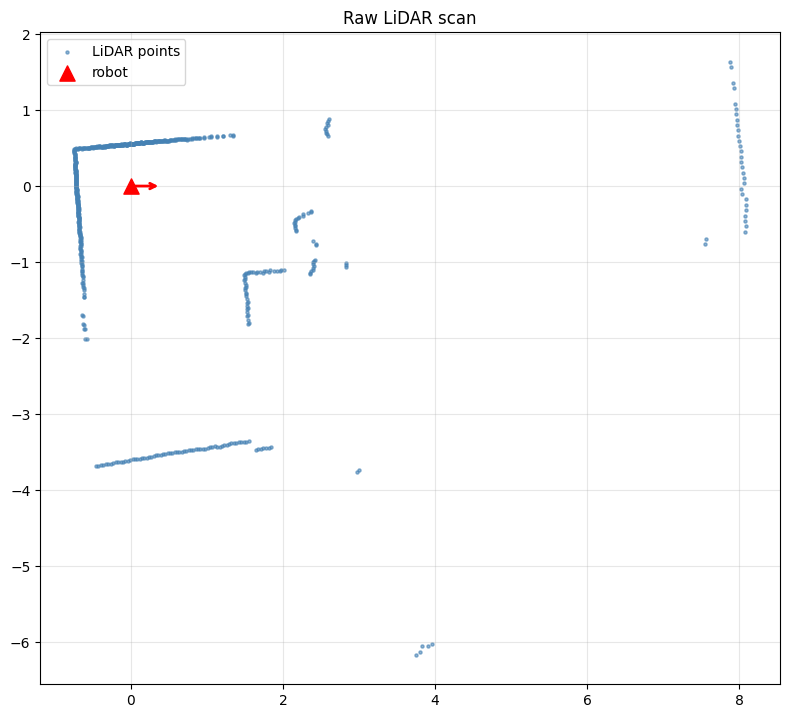

In [10]:

fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(x, y, s=5, c='steelblue', alpha=0.6, label='LiDAR points')

# Robot marker at origin
ax.scatter(0, 0, c='red', s=120, marker='^', zorder=5, label='robot')
ax.annotate('', xy=(0.4, 0), xytext=(0, 0),
            arrowprops=dict(arrowstyle='->', color='red', lw=2))

ax.set_aspect('equal')
ax.grid(True, alpha=0.3)
ax.legend()
ax.set_title("Raw LiDAR scan")

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, f"scan_{expt_name}.png"),
            dpi=150, bbox_inches='tight')
plt.show()

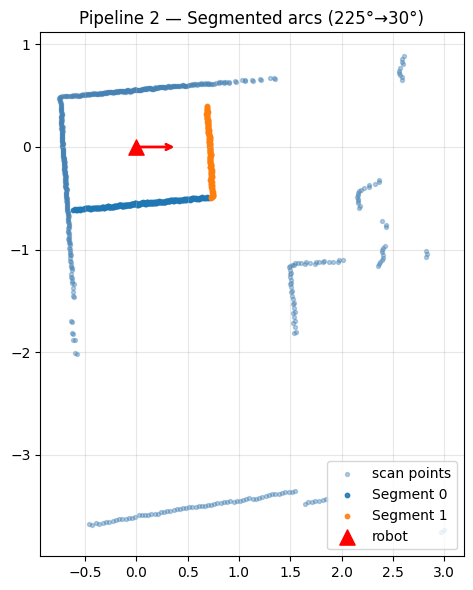

In [11]:
# ── Plot Full Scan + Segments ─────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(6, 6))

# Full scan points (within 5 m)
mask = r < 5.0
ax.scatter(x[mask], y[mask], s=8, c='steelblue', alpha=0.4, label='scan points')

# Plot each segmented arc in a different color
colors = plt.cm.tab10.colors
for i, (_, _, sxy) in enumerate(segments):
    ax.scatter(sxy[:, 0], sxy[:, 1], s=10,
               color=colors[i % len(colors)], alpha=0.9, label=f'Segment {i}')

# Robot marker (triangle pointing forward)
robot_marker = plt.matplotlib.markers.MarkerStyle('^')
robot_marker._transform.rotate_deg(0)  # 0° beam direction
ax.scatter(0, 0, c='red', s=120, marker=robot_marker, zorder=5, label='robot')

# Heading arrow
ax.annotate('', xy=(0.4, 0), xytext=(0, 0),
            arrowprops=dict(arrowstyle='->', color='red', lw=2))

# Centered view around robot
# ax.set_xlim(-1.5, 2.5)
# ax.set_ylim(-1, 1.5)

ax.set_aspect('equal')
ax.grid(True, alpha=0.3)
ax.legend()
ax.set_title(f"Pipeline 2 — Segmented arcs (225°→30°)")
plt.tight_layout()
plt.show()


In [ ]:
fits = smart_fit_segments(segments, min_points=8)
fits = merge_collinear(fits)

terminal_edges = detect_terminal_edges_from_fits(
    fits,
    ranges_raw=ranges,
    angles_full_rad=angles_full,
    max_range_interest=2.0,
    lookahead_beams=12,
    min_far_ratio=0.40,
    debug=True,
)



  fit_segment: distance=0.567m  ratio=4410.2  centroid=(0.236,-0.623)
  fit_segment: ACCEPTED
Seg 0: clean  ratio=4410.2  inliers=109/109 (100%)  d=0.567m  edge=(1.919,-0.946) @ 333.8°
Wall 0: single segment  pts=109  d=0.567m  normal=[0.190, 0.982]
Terminal check fit 0: edge_angle=333.8, edge_pt=(1.919,-0.946), far_ratio=1.00, ahead_ranges=[2.32 2.48 2.67 2.89 3.18 3.52 3.66 3.65 3.66 3.64 3.63 3.63]


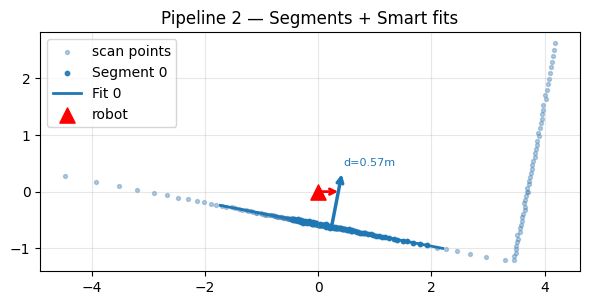

In [ ]:
# ── Plot Full Scan + Segments + Smart Fits ────────────────────────────────
fig, ax = plt.subplots(figsize=(6, 6))

# Full scan points (within 5 m)
mask = r < 5.0
ax.scatter(x[mask], y[mask], s=8, c='steelblue', alpha=0.4, label='scan points')

# Plot each segment in a different color
colors = plt.cm.tab10.colors
for i, (_, _, sxy) in enumerate(segments):
    ax.scatter(sxy[:, 0], sxy[:, 1], s=10,
               color=colors[i % len(colors)], alpha=0.9, label=f'Segment {i}')

# Overlay fitted lines from smart_fit_segments
for j, (f, sxy) in enumerate(fits):
    n, d, c = f['normal'], f['distance'], f['centroid']

    # line direction = perpendicular to normal
    wall_dir = np.array([-n[1], n[0]])

    # extend line through centroid
    p1 = c + wall_dir * 2.0
    p2 = c - wall_dir * 2.0
    ax.plot([p1[0], p2[0]], [p1[1], p2[1]],
            color=colors[j % len(colors)], lw=2, label=f'Fit {j}')

    # draw normal arrow from centroid toward robot
    ax.annotate('', xy=(c[0] + n[0], c[1] + n[1]), xytext=(c[0], c[1]),
                arrowprops=dict(arrowstyle='->', color=colors[j % len(colors)], lw=2.5))

    # label with distance
    ax.text(c[0] + n[0]*1.1, c[1] + n[1]*1.1,
            f'd={d:.2f}m', color=colors[j % len(colors)], fontsize=8)

# Robot marker (triangle pointing forward)
robot_marker = plt.matplotlib.markers.MarkerStyle('^')
robot_marker._transform.rotate_deg(0)  # 0° beam direction
ax.scatter(0, 0, c='red', s=120, marker=robot_marker, zorder=5, label='robot')

# Heading arrow
ax.annotate('', xy=(0.4, 0), xytext=(0, 0),
            arrowprops=dict(arrowstyle='->', color='red', lw=2))

# Centered view around robot
# ax.set_xlim(-1.5, 2.5)
# ax.set_ylim(-1, 1.5)

ax.set_aspect('equal')
ax.grid(True, alpha=0.3)
ax.legend()
ax.set_title("Pipeline 2 — Segments + Smart fits")
plt.tight_layout()
plt.show()


In [ ]:
result = detect_best_corner(fits)

In [ ]:
events = []

if result is not None:
    events.append({
        "type": result["type"],
        "point": result["vertex"],
        "radian_diff": result["radian_diff"],
        "angle_deg": result["angle_deg"],
        "turn_dir": "CCW" if result["radian_diff"] > 0 else "CW",
        "source": "line_intersection",
    })

for e in terminal_edges:
    events.append({
        "type": "EXTERNAL_EDGE",
        "point": e["point"],
        "radian_diff": -np.pi / 2,   # CW 90° default
        "angle_deg": 90.0,
        "turn_dir": "CW",
        "source": "terminal_dropout",
        "seg_idx": e["seg_idx"],
        "far_ratio": e["far_ratio"],
    })

def event_sort_key(ev):
    d = np.linalg.norm(ev["point"])
    return d

events.sort(key=event_sort_key)

# after distance sort, only swap INTERNAL ahead if comparable
COMPARABLE_DIST = 0.40  # meters

for i, ev in enumerate(events):
    if ev["type"] == "INTERNAL":
        internal = ev
        break
else:
    internal = None

if internal is not None:
    d_int = np.linalg.norm(internal["point"])

    closer_ext = [
        ev for ev in events
        if ev["type"] in ("EXTERNAL", "EXTERNAL_EDGE")
        and np.linalg.norm(ev["point"]) < d_int
    ]

    if closer_ext:
        d_ext = min(np.linalg.norm(ev["point"]) for ev in closer_ext)

        if abs(d_int - d_ext) < COMPARABLE_DIST:
            events.remove(internal)
            events.insert(0, internal)

for ev in events:
    p = ev["point"]
    print(
        f"{ev['type']} source={ev['source']} "
        f"turn={ev['turn_dir']} {ev['angle_deg']:.1f}° "
        f"pt=({p[0]:.3f},{p[1]:.3f})"
    )

EXTERNAL_EDGE source=terminal_dropout turn=CW 90.0° pt=(1.919,-0.946)


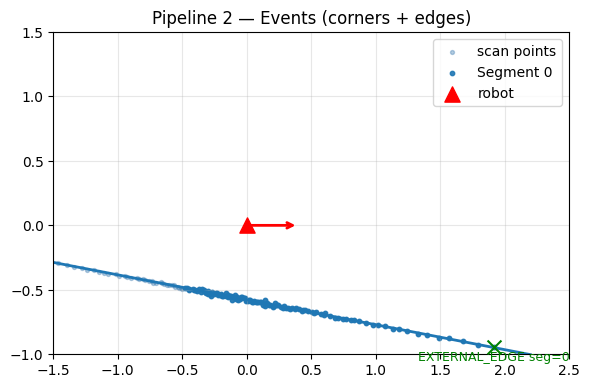

In [ ]:
# ── Plot Full Scan + Segments + Events ────────────────────────────────────
fig, ax = plt.subplots(figsize=(6, 6))

# Full scan points (within 5 m)
mask = r < 5.0
ax.scatter(x[mask], y[mask], s=8, c='steelblue', alpha=0.4, label='scan points')

# Segments in different colors
colors = plt.cm.tab10.colors
for i, (_, _, sxy) in enumerate(segments):
    ax.scatter(sxy[:, 0], sxy[:, 1], s=10,
               color=colors[i % len(colors)], alpha=0.9, label=f'Segment {i}')

# Overlay fits (optional, same as before)
for j, (f, sxy) in enumerate(fits):
    if f is None:
        continue
    n, c = f['normal'], f['centroid']
    wall_dir = np.array([-n[1], n[0]])
    p1, p2 = c + wall_dir * 2.0, c - wall_dir * 2.0
    ax.plot([p1[0], p2[0]], [p1[1], p2[1]],
            color=colors[j % len(colors)], lw=2)

# Plot events
for e in events:
    px, py = e["point"]
    if e["type"] in ["INTERNAL", "EXTERNAL"]:
        ax.scatter(px, py, c='magenta', s=120, marker='o', zorder=6)
        ax.text(px, py - 0.1,
                f"{e['type']} {e['angle_deg']:.1f}°",
                color='magenta', fontsize=9, ha='center')
    elif e["type"] == "EXTERNAL_EDGE":
        ax.scatter(px, py, c='green', s=100, marker='x', zorder=6)
        ax.text(px, py - 0.1,
                f"{e['type']} seg={e['seg_idx']}",
                color='green', fontsize=9, ha='center')

# Robot marker
robot_marker = plt.matplotlib.markers.MarkerStyle('^')
robot_marker._transform.rotate_deg(0)
ax.scatter(0, 0, c='red', s=120, marker=robot_marker, zorder=5, label='robot')

# Heading arrow
ax.annotate('', xy=(0.4, 0), xytext=(0, 0),
            arrowprops=dict(arrowstyle='->', color='red', lw=2))

ax.set_xlim(-1.5, 2.5)
ax.set_ylim(-1, 1.5)
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)
ax.legend()
ax.set_title("Pipeline 2 — Events (corners + edges)")
plt.tight_layout()
plt.show()
